# Short-Term Rental Guest Feedback: Phase 2

INFO 4360 course project, Phase 2 (descriptive and exploratory work). Path B: find what guests complain about, where and when, so the COO knows what to fix first.

Data: Inside Airbnb, Broward County, FL, scraped 2026-06-29. The raw files are not in this repo (see `data/README.md`).

## 0. Setup

Load packages and the helper functions from `src/preprocessing.py`

In [1]:
import sys
sys.path.append("..")   # so the notebook can import from src/

import pandas as pd
import matplotlib.pyplot as plt

from src.preprocessing import strip_html, clean_text, looks_english, load_reviews

RAW = "../data/raw"   # reviews.csv.gz and listings.csv.gz go here

## 1. Data exploration

### 1.1 Size and coverage

In [2]:
# One row per review, joined with the details of its listing
df = load_reviews(RAW)

print("Reviews:", f"{len(df):,}")
print("Listings with reviews:", f"{df.listing_id.nunique():,}")
print("Dates:", df.date.min().date(), "to", df.date.max().date())
df.drop(columns="comments").head(3)   # text left out here on purpose

Reviews: 703,398
Listings with reviews: 14,249
Dates: 2011-08-23 to 2026-07-01


,listing_id,id,date,neighbourhood_cleansed,property_type,room_type,review_scores_rating,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location
0,4879228,24982610,2015-01-04,Pompano Beach,Room in aparthotel,Entire home/apt,4.0,4.50,4.50,5.00,4.00
1,4879228,1650842821850841956,2026-03-27,Pompano Beach,Room in aparthotel,Entire home/apt,4.0,4.50,4.50,5.00,4.00
2,4909030,25770307,2015-01-25,Fort Lauderdale,Private room in home,Private room,4.9,4.91,4.94,4.94,4.93


### 1.2 Missing values

In [3]:
# Share of missing values in each column (%)
(df.isna().mean() * 100).round(2).sort_values(ascending=False)

comments                       0.04
listing_id                     0.00
id                             0.00
date                           0.00
neighbourhood_cleansed         0.00
property_type                  0.00
room_type                      0.00
review_scores_rating           0.00
review_scores_cleanliness      0.00
review_scores_checkin          0.00
review_scores_communication    0.00
review_scores_location         0.00
dtype: float64

In [4]:
# Drop the reviews with no text, the only column we cannot work without
df = df[df.comments.notna()].copy()
print("Reviews with text:", f"{len(df):,}")

Reviews with text: 703,149


### 1.3 Reviews over time

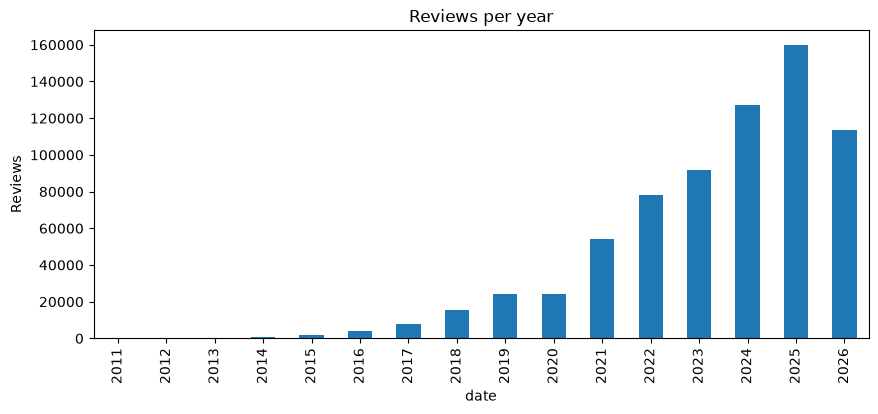

In [5]:
reviews_per_year = df.date.dt.year.value_counts().sort_index()

reviews_per_year.plot(kind="bar", figsize=(10, 4), title="Reviews per year")
plt.ylabel("Reviews")
plt.show()

### 1.4 Review sub-scores

There is no label for each review, but every listing has sub-scores from 1 to 5. One row per listing here, so big listings don't count more.

In [6]:
scores = ["review_scores_rating", "review_scores_cleanliness", "review_scores_communication",
          "review_scores_checkin", "review_scores_location"]
listing_scores = df.drop_duplicates("listing_id")[scores]
listing_scores.describe().round(2)

,review_scores_rating,review_scores_cleanliness,review_scores_communication,review_scores_checkin,review_scores_location
count,14247.00,14246.00,14246.00,14245.00,14245.00
mean,4.72,4.72,4.82,4.81,4.80
std,0.45,0.44,0.39,0.41,0.34
min,1.00,0.00,0.00,0.00,0.00
25%,4.67,4.65,4.80,4.79,4.75
50%,4.85,4.85,4.93,4.94,4.89
75%,4.98,4.98,5.00,5.00,5.00
max,5.00,5.00,5.00,5.00,5.00


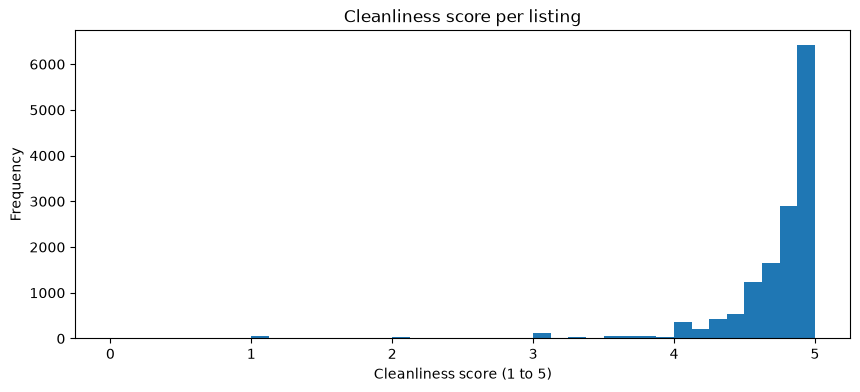

In [7]:
listing_scores.review_scores_cleanliness.plot(kind="hist", bins=40, figsize=(10, 4),
                                              title="Cleanliness score per listing")
plt.xlabel("Cleanliness score (1 to 5)")
plt.show()

### 1.5 Text length and language

count    703149.0
mean         36.8
std          40.1
min           1.0
25%          11.0
50%          24.0
75%          48.0
max        1298.0
Name: words, dtype: float64


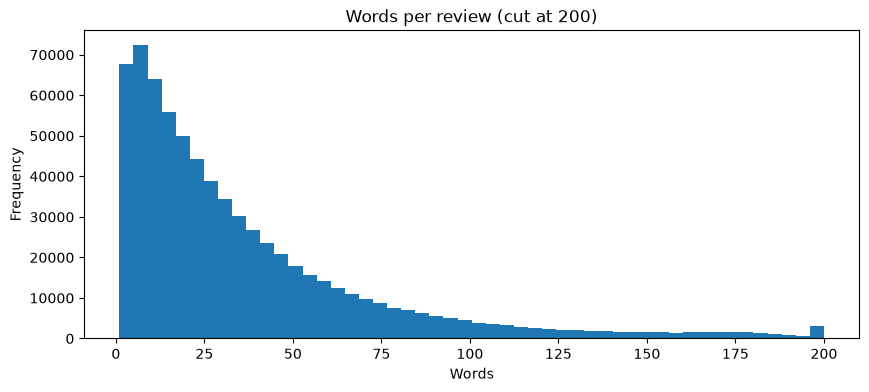

In [8]:
df["words"] = df.comments.str.split().str.len()
print(df.words.describe().round(1))

df.words.clip(upper=200).plot(kind="hist", bins=50, figsize=(10, 4),
                              title="Words per review (cut at 200)")
plt.xlabel("Words")
plt.show()

In [9]:
# Rough language check from src/preprocessing.py (share of common English words)
df["english"] = df.comments.map(looks_english)

print("English:", f"{df.english.mean():.0%}")
print("Very short (5 words or less):", f"{(df.words <= 5).mean():.0%}")
print("With HTML line breaks (<br/>):", f"{df.comments.str.contains('<br', regex=False).mean():.0%}")

English: 84%
Very short (5 words or less): 12%
With HTML line breaks (<br/>): 12%


### 1.6 What a review looks like

Inside Airbnb asks users not to republish its data, and this repo is public, so the examples below come from `data/sample_mock.csv`: made-up reviews in the same format, written to look like the real ones (praise, a broken AC, noise, a lockbox problem).

In [10]:
mock = pd.read_csv("../data/sample_mock.csv")
for text in mock.comments.head(5):
    print("-", text)

- Great location, two blocks from the beach. The place was spotless and check-in was easy.
- The air conditioning stopped working on the second night and it took a day to get someone to fix it.
- Very noisy at night. Loud music from the neighbors until 2am and nobody answered when we called.
- Nice view and comfortable beds. A bit dusty in the bathroom but nothing major.
- We could not find the lockbox and waited an hour outside with our luggage. Instructions were confusing.


### What the exploration tells us

- About 700,000 reviews of 14,000 listings, and most of them are recent: 2024 and 2025 are the biggest years. So recent years give plenty of data to compare areas and seasons.
- Missing values are not a problem. Only 249 reviews have no text.
- The sub-scores are packed near the top (median cleanliness 4.85 out of 5). That is the problem from Phase 1: the scores barely separate good homes from bad ones, so the useful signal has to come from the text.
- Reviews are short (median 24 words) and 12% have 5 words or less, like "Great place!". Short reviews say little about specific problems.
- 84% are in English. The text tools we use (VADER, English stop words) only work in English, so the rest of the analysis keeps English reviews only.

## 2. Text mining basics

### 2.1 Working sample

English reviews from 2023 on, and a random 30,000 of them so everything runs in a few seconds. Recent reviews matter most to the COO, and the tools below only work in English.

In [11]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud

recent = df[df.english & (df.date >= "2023-01-01")]
sample = recent.sample(30000, random_state=42).copy()

sample["text"] = sample.comments.map(strip_html)    # for VADER: keeps case and punctuation
sample["clean"] = sample.comments.map(clean_text)   # for word counts: lowercase, letters only
print("English reviews since 2023:", f"{len(recent):,}", "| sample:", f"{len(sample):,}")

English reviews since 2023: 408,181 | sample: 30,000


### 2.2 Top keywords

Words that show up in almost every review ("place", "stay", "great", "host") are added to the stop words, otherwise they fill the whole chart.

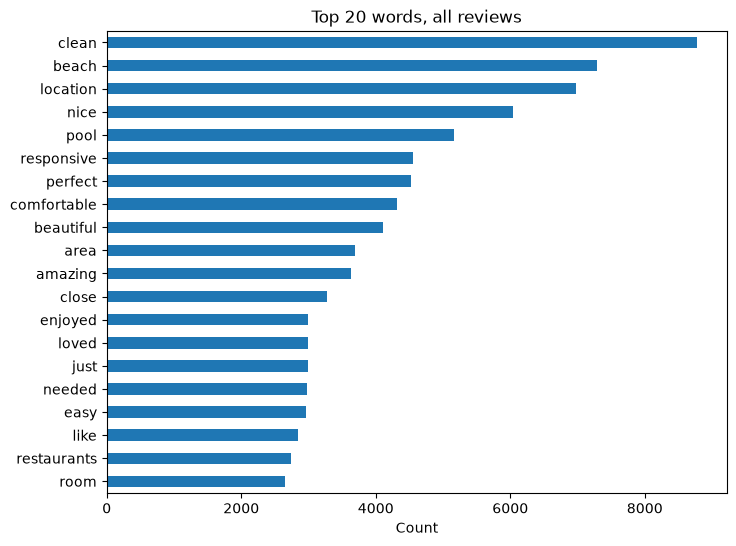

In [12]:
DOMAIN_STOP_WORDS = ["place", "stay", "great", "host", "home", "house", "airbnb", "would",
                     "definitely", "recommend", "everything", "really", "us", "also", "time"]
STOP_WORDS = list(ENGLISH_STOP_WORDS.union(DOMAIN_STOP_WORDS))

def top_terms(texts, n=20, ngram_range=(1, 1), stop_words=STOP_WORDS):
    """Count words (or word pairs) across the texts and return the n most frequent."""
    vectorizer = CountVectorizer(stop_words=stop_words, ngram_range=ngram_range, min_df=5)
    counts = vectorizer.fit_transform(texts).sum(axis=0).A1
    return pd.Series(counts, index=vectorizer.get_feature_names_out()).sort_values(ascending=False).head(n)

def plot_terms(terms, title):
    terms.sort_values().plot(kind="barh", figsize=(8, 6), title=title)
    plt.xlabel("Count")
    plt.show()

plot_terms(top_terms(sample.clean), "Top 20 words, all reviews")

### 2.3 Baseline sentiment with VADER

VADER gives each review a compound score from -1 (very negative) to +1 (very positive). The usual cutoffs are below -0.05 for negative and above 0.05 for positive.

sentiment
positive    95.4
negative     2.4
neutral      2.2
Name: proportion, dtype: float64


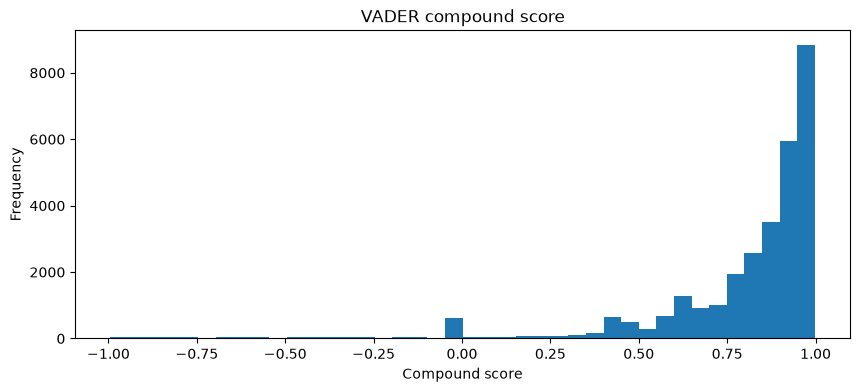

In [13]:
analyzer = SentimentIntensityAnalyzer()
sample["compound"] = sample.text.map(lambda t: analyzer.polarity_scores(t)["compound"])

def vader_label(score):
    if score < -0.05:
        return "negative"
    if score > 0.05:
        return "positive"
    return "neutral"

sample["sentiment"] = sample.compound.map(vader_label)
print((sample.sentiment.value_counts(normalize=True) * 100).round(1))

sample.compound.plot(kind="hist", bins=40, figsize=(10, 4), title="VADER compound score")
plt.xlabel("Compound score")
plt.show()

### 2.4 What negative reviews talk about

Single words, then word pairs. For pairs only the standard English stop words are removed, so pairs like "didn work" and "hot water" survive.

Negative reviews in the sample: 708


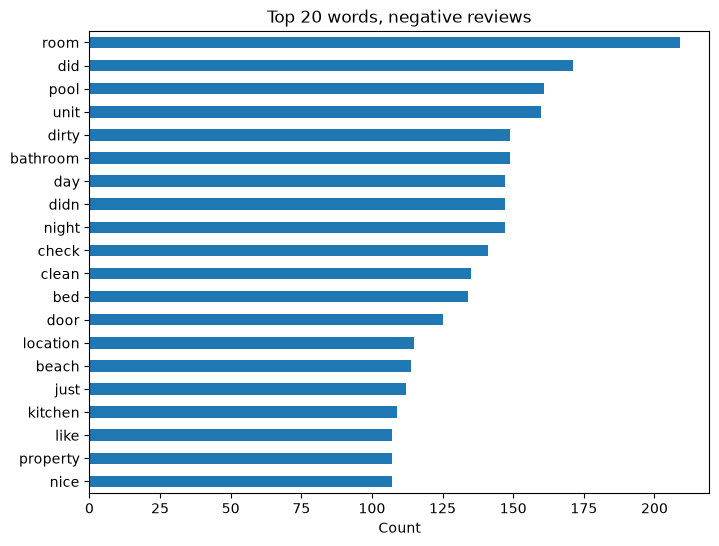

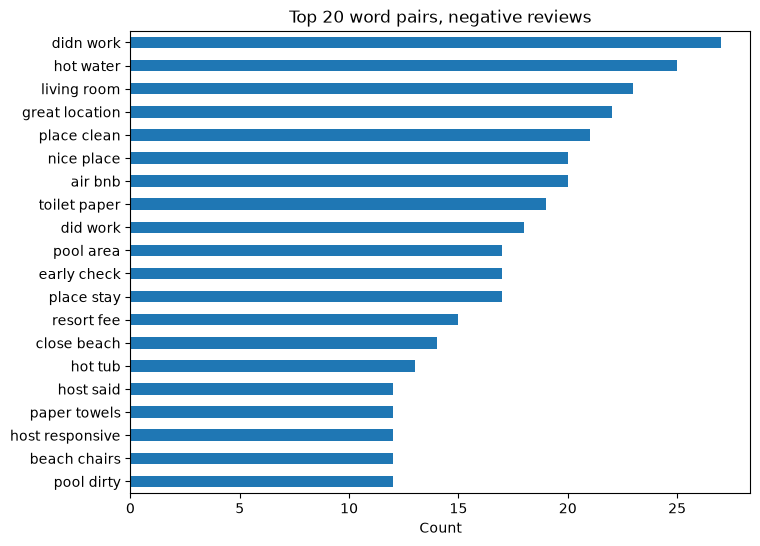

In [14]:
negative = sample[sample.sentiment == "negative"]
print("Negative reviews in the sample:", len(negative))

plot_terms(top_terms(negative.clean), "Top 20 words, negative reviews")
plot_terms(top_terms(negative.clean, ngram_range=(2, 2), stop_words="english"),
           "Top 20 word pairs, negative reviews")

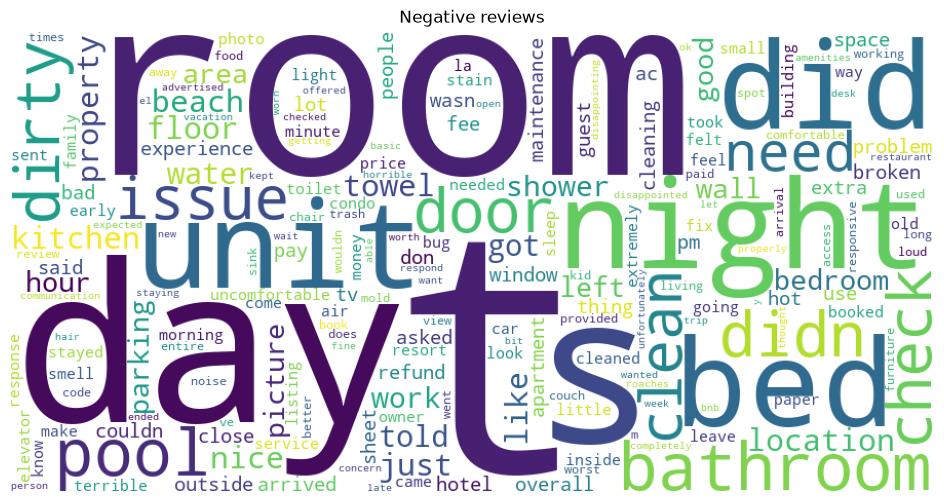

In [15]:
cloud = WordCloud(width=900, height=450, background_color="white", stopwords=set(STOP_WORDS),
                  collocations=False, random_state=42).generate(" ".join(negative.clean))
plt.figure(figsize=(12, 6))
plt.imshow(cloud)
plt.axis("off")
plt.title("Negative reviews")
plt.show()

### 2.5 A first look at the aspects

A simple keyword rule per aspect, as a baseline for the Claude labels in Phase 3. A review "mentions" an aspect if it contains one of its words. For each aspect: how often it is mentioned, how often those mentions are negative, and how much of all negative reviews it covers.

In [16]:
ASPECTS = {
    "cleanliness": r"\b(?:clean|dirty|filthy|stain|stains|smell|smelled|smelly|dust|dusty|hair|bugs|roaches|ants)\b",
    "maintenance": r"\b(?:broken|ac|air conditioning|leak|leaking|plumbing|toilet|shower|hot water|wifi|repair|not working|didn t work)\b",
    "host_communication": r"\b(?:host|communication|responsive|respond|responded|reply|replied)\b",
    "check_in": r"\b(?:check in|checkin|check out|checkout|key|keys|code|lock|lockbox)\b",
    "location": r"\b(?:location|located|beach|walk|walking|walkable|close to|restaurants|downtown)\b",
    "noise": r"\b(?:noise|noisy|loud|quiet)\b",
}

def aspect_table(data):
    is_negative = data.sentiment == "negative"
    rows = []
    for aspect, pattern in ASPECTS.items():
        mentioned = data.clean.str.contains(pattern, regex=True)
        rows.append({"aspect": aspect,
                     "mentioned_%": mentioned.mean() * 100,
                     "negative_%_when_mentioned": is_negative[mentioned].mean() * 100,
                     "share_of_negative_reviews_%": mentioned[is_negative].mean() * 100})
    return pd.DataFrame(rows).set_index("aspect").round(1)

aspects = aspect_table(sample)
aspects

,mentioned_%,negative_%_when_mentioned,share_of_negative_reviews_%
aspect,,,
cleanliness,29.4,3.4,41.9
maintenance,5.3,13.4,30.2
host_communication,34.2,2.1,30.8
check_in,7.6,6.1,19.9
location,41.1,1.6,28.7
noise,9.8,2.6,10.7


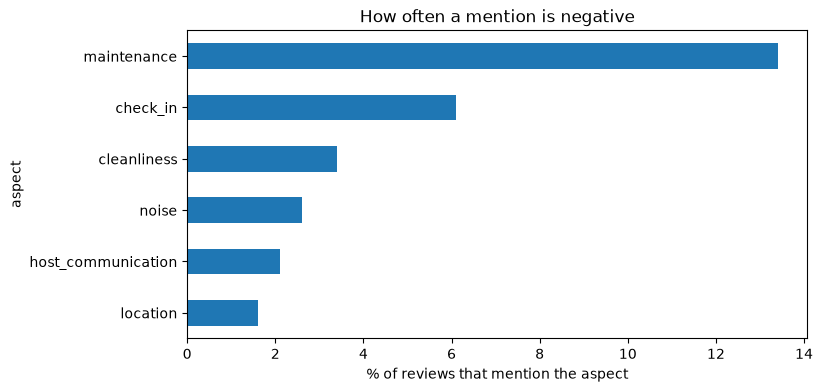

In [17]:
aspects["negative_%_when_mentioned"].sort_values().plot(kind="barh", figsize=(8, 4),
                                                        title="How often a mention is negative")
plt.xlabel("% of reviews that mention the aspect")
plt.show()

### 2.6 Does the text agree with the scores?

If the text carries real signal, homes with more negative reviews should have lower cleanliness scores. Listings with at least 5 reviews in the sample.

In [18]:
per_listing = sample.groupby("listing_id").agg(
    reviews=("compound", "size"),
    negative_share=("sentiment", lambda s: (s == "negative").mean()),
    cleanliness=("review_scores_cleanliness", "first"))
per_listing = per_listing[per_listing.reviews >= 5]

print("Listings:", len(per_listing))
print("Correlation, negative share vs cleanliness score:",
      round(per_listing.negative_share.corr(per_listing.cleanliness), 2))

bands = pd.cut(per_listing.cleanliness, [0, 4.5, 4.8, 5], labels=["below 4.5", "4.5 to 4.8", "above 4.8"])
(per_listing.groupby(bands, observed=True).negative_share.mean() * 100).round(1).rename("% negative reviews")

Listings: 2207
Correlation, negative share vs cleanliness score: -0.24


cleanliness
below 4.5     5.0
4.5 to 4.8    3.3
above 4.8     1.2
Name: % negative reviews, dtype: float64

### 2.7 Where the negative reviews are

In [19]:
top_areas = sample.neighbourhood_cleansed.value_counts().head(8).index
by_area = sample[sample.neighbourhood_cleansed.isin(top_areas)].groupby("neighbourhood_cleansed").agg(
    reviews=("sentiment", "size"),
    negative_pct=("sentiment", lambda s: round((s == "negative").mean() * 100, 1)))
by_area.sort_values("negative_pct", ascending=False)

,reviews,negative_pct
neighbourhood_cleansed,,
Hallandale Beach,1188,4.4
Dania Beach,1084,3.1
Hollywood,6251,3.1
Fort Lauderdale,10945,2.0
Oakland Park,1203,1.9
Pompano Beach,2484,1.8
Wilton Manors,1594,1.8
Deerfield Beach,1424,1.5


### What the text mining tells us

- The top words are almost all praise: clean, beach, location, pool, responsive. Guests write about location and cleanliness more than anything else.
- VADER rates 95% of the reviews as positive and only 2.4% as negative (708 of 30,000). Complaints are rare and easy to miss. For Phase 3 that means a random sample would have very few complaints, so we will add extra reviews that VADER scores low.
- Negative reviews talk about the room, bathroom, pool and check-in, and the word pairs point to concrete problems: "didn work", "hot water", "toilet paper", "early check", "pool dirty", "resort fee".
- Cleanliness is the biggest complaint by volume: it shows up in 42% of the negative reviews. Maintenance is mentioned in only 5% of reviews, but when it is, 13% of those reviews are negative, the highest rate of any aspect. For the COO that suggests cleaning is the most common problem and maintenance the sharpest one.
- The text agrees with the scores. Homes with a cleanliness score below 4.5 get 5.0% negative reviews, against 1.2% for homes above 4.8 (correlation -0.24 across 2,207 homes). So the text carries real signal, and the aspects can explain what is behind a low score.
- Some areas do worse: Hallandale Beach has 4.4% negative reviews, more than twice Fort Lauderdale's 2.0%. That is the kind of "where" the COO asked about, and Phase 3 will break it down by aspect.
- The keyword rules are rough. "clean" counts as a cleanliness mention whether the guest liked it or not, and VADER misses sarcasm and mixed reviews. That is why Phase 3 uses Claude to label each aspect as positive, negative or not mentioned.
- No topic model here. On our very short reviews (median 24 words) LDA groups words badly, as we saw in class, and the aspects we care about are already known.

## 3. Plan for Phase 3

### 3.1 Path B, and why

We follow Path B (understanding and extraction). The COO does not need a model that predicts a cleanliness score, because that score already exists. The COO needs to know what guests complain about, where and when, so the money goes to the right fix. Section 1 showed the scores are packed near 5 and barely tell homes apart, and Section 2 showed the text does carry signal (more negative reviews in homes with lower scores). The deliverable is a set of patterns with clear, measured recommendations, for example "maintenance complaints are most common in area X in summer".

### 3.2 What Claude will do

The keyword rules in 2.5 can't tell praise from complaints ("clean" counts either way). Claude will read each review and, for a fixed list of aspects with short definitions, say whether the review is **positive**, **negative** or **not mentioned** about each one, with a short quote as evidence.

- Aspects: cleanliness, maintenance, host communication, check-in, location (from the README). The test in 3.3 showed that noise and parking need their own aspects, so we will add them.
- Sample: about 1,500 English reviews from 2023 on. 1,000 random, plus 500 extra with a low VADER score, because only 2.4% of reviews are negative and a random sample would have very few complaints. When we report shares we will weight the extra reviews back down.
- Check: we label 100 of the same reviews by hand and report how often we agree with Claude, aspect by aspect.
- Then: shares of negative mentions by area, property type and season, which is what the COO asked for.

### 3.3 Prompt test

A first test on the 12 made-up reviews in `data/sample_mock.csv`, so no real review leaves the computer and the results can live in this public repo. Each made-up review was written with a known problem, so we can check Claude against what we expect.

In [20]:
import os
import json
import anthropic
from dotenv import load_dotenv

ASPECT_DEFINITIONS = {
    "cleanliness": "how clean the place was: dirt, stains, smells, bugs, or praise for being clean or spotless",
    "maintenance": "things that work or are broken: air conditioning, plumbing, hot water, appliances, wifi, pool equipment",
    "host_communication": "how the host or manager responded: speed, helpfulness, answering calls or messages",
    "check_in": "getting in and out: instructions, keys, lockbox or door codes, check-in and check-out times",
    "location": "where the home is: distance to the beach, restaurants, shops, safety of the area",
}

aspect_schema = {
    "type": "object",
    "properties": {aspect: {"type": "object",
                            "properties": {"sentiment": {"type": "string",
                                                         "enum": ["positive", "negative", "not_mentioned"]},
                                           "evidence": {"type": "string"}},
                            "required": ["sentiment", "evidence"],
                            "additionalProperties": False}
                   for aspect in ASPECT_DEFINITIONS},
    "required": list(ASPECT_DEFINITIONS),
    "additionalProperties": False,
}

PROMPT = '''You label guest reviews of short-term rental homes for the operations team.
For each aspect below, decide if the review is positive, negative, or does not mention it.

Aspects:
{aspects}

Rules:
- Use "not_mentioned" unless the review says something about that aspect.
- A review can be positive about one aspect and negative about another.
- For evidence, quote the exact words from the review, or leave it empty if not mentioned.

<review>
{review}
</review>'''

MODEL = "claude-haiku-5-5"
PRICES = (0.10, 0.50)   # USD per 1 million input and output tokens for Haiku (class notebook)

def label_review(client, review):
    """Ask Claude for the sentiment of each aspect in one review. Returns (labels, usage)."""
    aspects = "\n".join(f"- {name}: {meaning}" for name, meaning in ASPECT_DEFINITIONS.items())
    response = client.messages.create(
        model=MODEL,
        max_tokens=1024,
        messages=[{"role": "user", "content": PROMPT.format(aspects=aspects, review=review)}],
        output_config={"effort": "low", "format": {"type": "json_schema", "schema": aspect_schema}},
    )
    text = next(block.text for block in response.content if block.type == "text")
    return json.loads(text), response.usage

In [21]:
# Runs the test once and saves it, so re-running the notebook does not pay again.
# Needs ANTHROPIC_API_KEY in a .env file or in the environment; without it this cell just skips.
RESULTS_FILE = "../data/claude_prompt_test_mock.json"
load_dotenv(override=True)   # a key in .env wins over an old key saved in Windows

if os.path.exists(RESULTS_FILE):
    test = json.load(open(RESULTS_FILE))
    print("Loaded saved test results")
elif os.getenv("ANTHROPIC_API_KEY"):
    client = anthropic.Anthropic()
    test = []
    for row in mock.itertuples():
        labels, usage = label_review(client, row.comments)
        test.append({"id": row.id, "labels": labels,
                     "input_tokens": usage.input_tokens, "output_tokens": usage.output_tokens})
    json.dump(test, open(RESULTS_FILE, "w"), indent=1)
    print("Labeled", len(test), "made-up reviews and saved the results")
else:
    test = []
    print("No API key found, skipping the Claude test")

Labeled 12 made-up reviews and saved the results


In [22]:
# What we expect for each made-up review (written with a known problem), to compare with Claude
EXPECTED = {
    9000001: {"cleanliness": "positive", "check_in": "positive", "location": "positive"},
    9000002: {"maintenance": "negative"},
    9000003: {"host_communication": "negative"},
    9000004: {"cleanliness": "negative"},
    9000005: {"check_in": "negative"},
    9000006: {"cleanliness": "positive"},
    9000007: {"cleanliness": "negative"},
    9000008: {},
    9000009: {"host_communication": "positive", "maintenance": "positive"},
    9000010: {},
    9000011: {"maintenance": "negative"},
    9000012: {"cleanliness": "positive"},
}

if test:
    rows = []
    for result in test:
        expected = EXPECTED[result["id"]]
        for aspect in ASPECT_DEFINITIONS:
            rows.append({"id": result["id"], "aspect": aspect,
                         "expected": expected.get(aspect, "not_mentioned"),
                         "claude": result["labels"][aspect]["sentiment"]})
    check = pd.DataFrame(rows)
    check["agree"] = check.expected == check.claude
    print(f"Claude agrees with our expected labels on {check.agree.mean():.0%} of {len(check)} decisions")
    display(check.pivot(index="id", columns="aspect", values="claude"))
    display(check[~check.agree])

Claude agrees with our expected labels on 95% of 60 decisions


aspect,check_in,cleanliness,host_communication,location,maintenance
id,,,,,
9000001,positive,positive,not_mentioned,positive,not_mentioned
9000002,not_mentioned,not_mentioned,negative,not_mentioned,negative
9000003,not_mentioned,not_mentioned,negative,negative,not_mentioned
9000004,not_mentioned,negative,not_mentioned,not_mentioned,not_mentioned
9000005,negative,not_mentioned,not_mentioned,not_mentioned,not_mentioned
9000006,not_mentioned,positive,not_mentioned,not_mentioned,not_mentioned
9000007,not_mentioned,negative,not_mentioned,not_mentioned,not_mentioned
9000008,not_mentioned,not_mentioned,not_mentioned,not_mentioned,not_mentioned
9000009,not_mentioned,not_mentioned,positive,not_mentioned,positive


,id,aspect,expected,claude,agree
7,9000002,host_communication,not_mentioned,negative,False
14,9000003,location,not_mentioned,negative,False
49,9000010,location,not_mentioned,negative,False


In [23]:
# Cost estimate from the real token counts of the test
if test:
    tokens_in = sum(r["input_tokens"] for r in test) / len(test)
    tokens_out = sum(r["output_tokens"] for r in test) / len(test)
    per_review = (tokens_in * PRICES[0] + tokens_out * PRICES[1]) / 1e6
    print(f"Per review: {tokens_in:.0f} input + {tokens_out:.0f} output tokens = ${per_review:.5f}")
    for n in [1_500, len(recent)]:
        print(f"{n:>9,} reviews: about ${n * per_review:,.2f}")

Per review: 1242 input + 152 output tokens = $0.00020
    1,500 reviews: about $0.30
  408,181 reviews: about $81.78


### What the test taught us

Claude agreed with our expected labels on 95% of the 60 decisions (12 reviews x 5 aspects), and the three disagreements are useful:

- "The air conditioning stopped working... it took a day to get someone to fix it": Claude also marked host communication as negative. Claude is right here, the slow response is the host's problem, and our expected labels were too strict.
- "Very noisy at night" and "Parking was a nightmare": with no noise or parking aspect, Claude put both under location. So Phase 3 will add **noise** and **parking** as their own aspects, otherwise location gets mixed with things the COO fixes in different ways.

Cost from the real token counts: about \$0.0002 per review, so the planned 1,500 reviews cost about \$0.30. All 408,181 recent English reviews would be about \$82, possible but not needed.

### 3.4 Concerns

- **Privacy.** The reviews are public, but Inside Airbnb asks us not to republish them, so the raw data stays out of this repo and the notebook only shows counts, charts and made-up examples. Claude only gets the review text, never reviewer names or ids. The API key lives in a `.env` file that `.gitignore` keeps off GitHub.
- **Scale and cost.** Labeling all English reviews since 2023 is possible but not needed. A sample of about 1,500 is enough to compare areas and seasons, and the test above gives the cost from real token counts.
- **Validity.** Claude can be wrong or read things that are not there. We will check 100 reviews by hand and report the agreement per aspect, keep the evidence quotes and check that they appear in the review, and keep the aspect list and definitions fixed so results are consistent between runs.
- **Rare complaints.** Only 2.4% of reviews are negative. Oversampling low VADER scores fixes the sample size, but we have to weight back when we report percentages.
- **Mixed and sarcastic reviews.** VADER misses these. The test above includes mixed reviews (good beds, dusty bathroom) to see if Claude separates the aspects.

## 4. Phase 2 update

**Done so far.** Path B is set (Phase 1 feedback). We explored 703,149 reviews of 14,249 homes, built reusable cleaning and loading functions (`src/preprocessing.py`), and ran keyword, sentiment and aspect baselines on 30,000 recent English reviews. We tested the Claude aspect prompt on 12 made-up reviews: it agreed with our expected labels on 95% of the decisions, at about \$0.0002 per review.

**What we found.** Scores are packed near 5, but the text is not: about 2.4% of reviews are negative, cleanliness is the most common complaint (42% of negative reviews), maintenance is the most likely to be negative when mentioned (13%), and homes with lower cleanliness scores get about four times as many negative reviews. Some areas, like Hallandale Beach, do worse than others.

**Next (Phase 3).** Label about 1,500 reviews with Claude, hand-check 100, then break down negative mentions by area, property type and season and turn them into recommendations for the COO.

**Team.** Guilherme led the code and the analysis. Manoj cloned the repo, reviewed the Path B plan and committed from his machine.

## AI Use Log

Tool: Claude (Claude Code), used as a coding assistant.

- Code. Claude drafted the helper functions in `src/preprocessing.py` and the notebook cells, following the methods from class (CountVectorizer, VADER, word clouds, the JSON schema prompt from Class 13). We ran every cell and checked the outputs.
- Writing. Claude drafted the interpretation and plan text from our outputs. We checked each number against the cells.
- Error caught. The first version printed three real reviews as examples. Inside Airbnb asks users not to republish its data and this repo is public, so we replaced them with the made-up reviews in `data/sample_mock.csv`.
- Prompt test. The Claude API test in 3.3 runs from our own notebook with the class project key, on made-up reviews only.